In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
pd.set_option("display.max_columns", None)

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Root Proyek: {ROOT}")
print(f"Folder data tersedia: {DATA_DIR.exists()}")

Root Proyek: c:\Users\Agata Corinna\Documents\Kuliah\Semester 5\Supervised Machine Learning\1 - PRAKTIKUM\Structural Damage Classification Kaggle
Folder data tersedia: True


In [31]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

In [32]:
print(f"Train: {train.shape}")
print(f"Test: {test.shape}")
print(f"Sample submission: {sample.shape}")

Train: (533465, 17)
Test: (228629, 16)
Sample submission: (228629, 2)


In [33]:
display(train.head())
display(test.head())
display(sample.head())

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure
0,122207000141,12,1205,120504,1,8,240,10,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,Rectangular,has_superstructure_mud_mortar_stone
1,284909000871,28,2810,281006,3,4,384,22,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
2,241904000231,24,2409,240909,2,999,384,21,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
3,248308000891,24,2412,241202,2,16,527,19,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
4,300405002981,30,3001,300104,2,6,280,16,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,has_superstructure_mud_mortar_stone


,building_id,damage_grade
0,122207000141,Grade 3
1,284909000871,Grade 1
2,241904000231,Grade 5
3,248308000891,Grade 4
4,300405002981,Grade 2


In [34]:
print(f"Kolom Train: \n{train.columns.tolist()}")

Kolom Train: 
['building_id', 'district_id', 'vdcmun_id', 'ward_id', 'count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'damage_grade', 'superstructure']


In [37]:
print(f"Informasi train: \n{train.info()}")

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [38]:
print(f"Statistik Deskriptif: \n{train.describe(include="all").T}")

Statistik Deskriptif: 
                           count unique                                  top  \
building_id             533465.0    NaN                                  NaN   
district_id             533465.0    NaN                                  NaN   
vdcmun_id               533465.0    NaN                                  NaN   
ward_id                 533465.0    NaN                                  NaN   
count_floors_pre_eq     533465.0    NaN                                  NaN   
age_building            533465.0    NaN                                  NaN   
plinth_area_sq_ft       533465.0    NaN                                  NaN   
height_ft_pre_eq        533465.0    NaN                                  NaN   
land_surface_condition    533465      3                                 Flat   
foundation_type           533465      5               Mud mortar-Stone/Brick   
roof_type                 533465      3             Bamboo/Timber-Light roof   
ground_floor_type

In [42]:
missing = pd.DataFrame({
    "jumlah": train.isnull().sum(),
    "persentase": (train.isnull().mean() * 100).round(2)
})

print("Missing Value train:")
display(missing[missing["jumlah"] > 0])

Missing Value train:


,jumlah,persentase


In [43]:
print(f"Jumlah Duplikat baris: {train.duplicated().sum()}")
print("Jumlah ID Duplikat:",
      train["building_id"].duplicated().sum()
      if "building_id" in train.columns else "ID tidak tersedia")

Jumlah Duplikat baris: 0
Jumlah ID Duplikat: 0


Proporsi kelas (%):


damage_grade
Grade 1    10.34
Grade 2    11.45
Grade 3    17.90
Grade 4    24.12
Grade 5    36.19
Name: proportion, dtype: float64

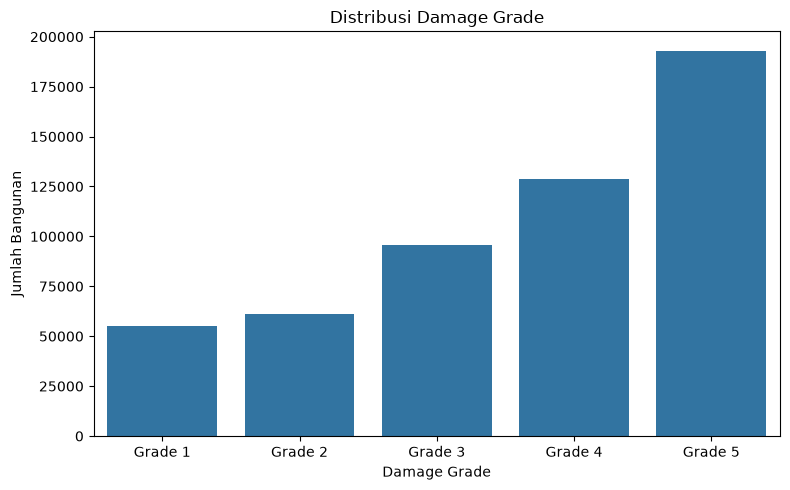

In [44]:
TARGET = "damage_grade"

if TARGET not in train.columns:
    raise ValueError(f"Kolom {TARGET} tidak ditemukan.")

print("Proporsi kelas (%):")
display(
    (train[TARGET].value_counts(normalize=True) * 100)
    .round(2)
    .sort_index()
)

plt.figure(figsize=(8, 5))
sns.countplot(data=train, x=TARGET, order=sorted(train[TARGET].dropna().unique()))
plt.title("Distribusi Damage Grade")
plt.xlabel("Damage Grade")
plt.ylabel("Jumlah Bangunan")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "damage_grade_distribution.png", dpi=150)
plt.show()

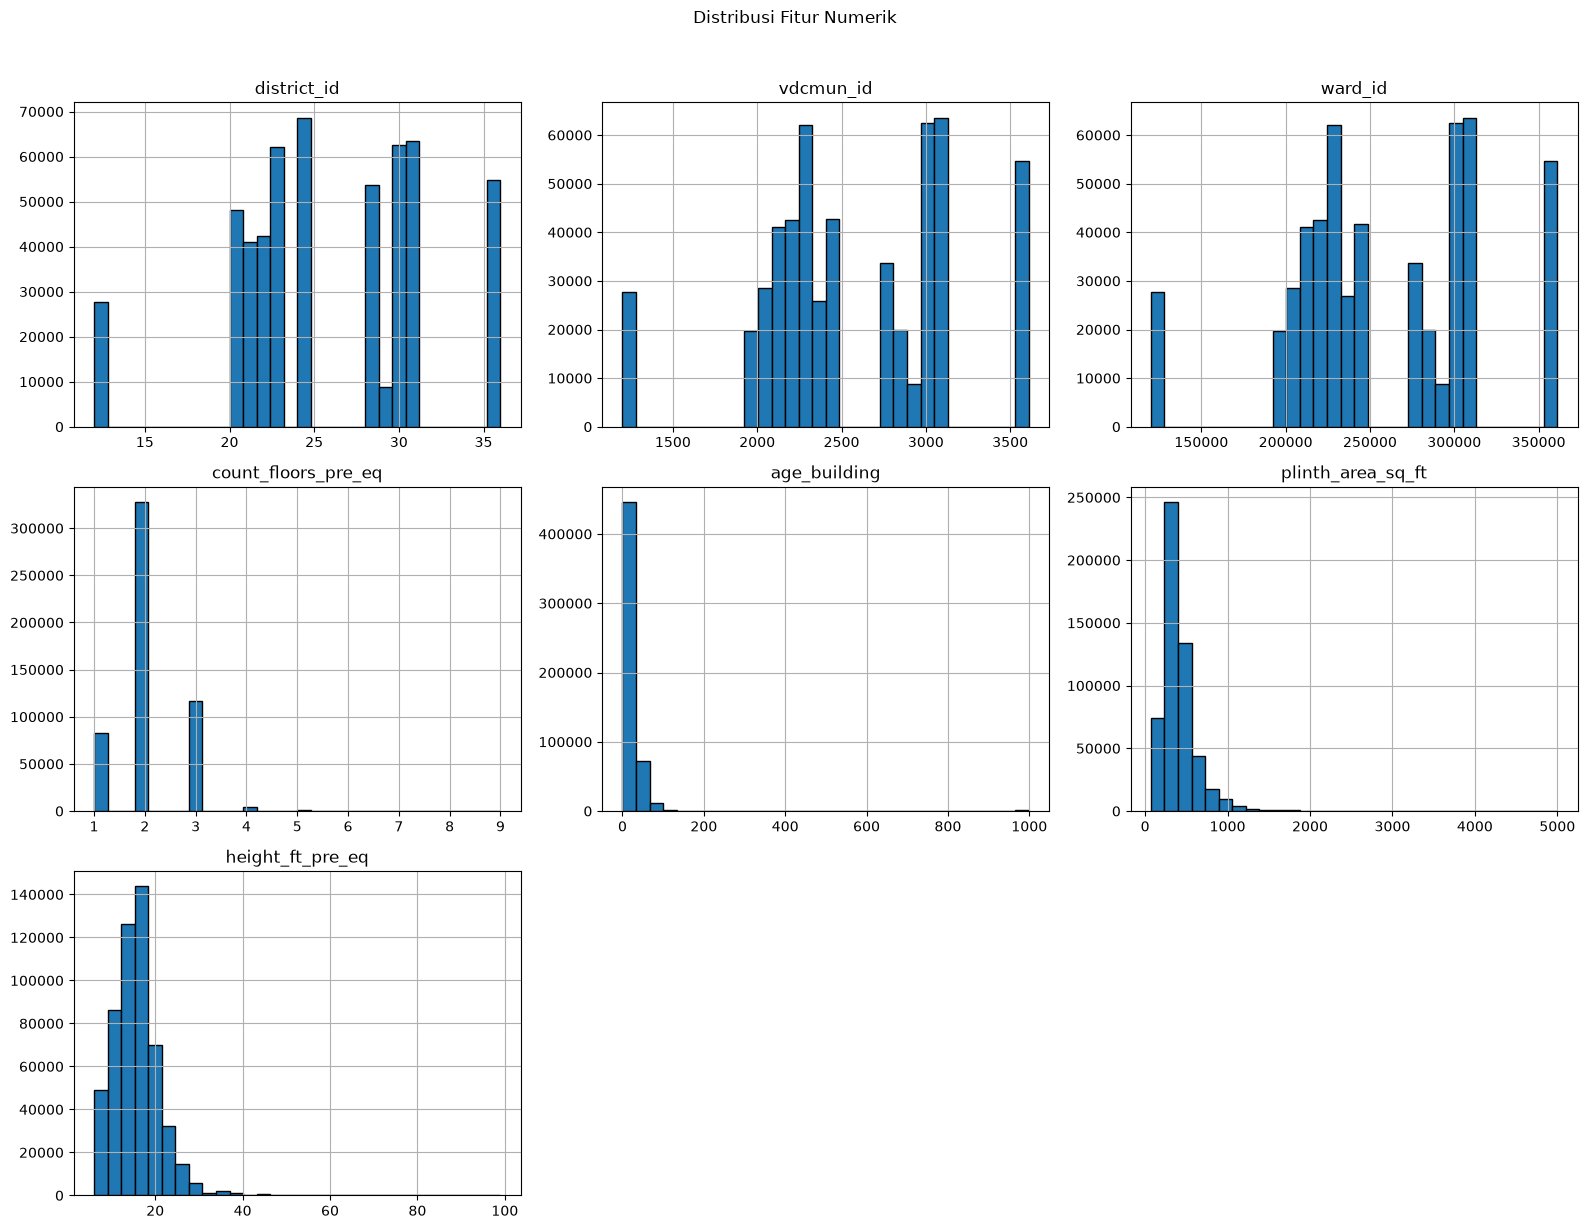

In [48]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()

for col in ["building_id", TARGET]:
    if col in numeric_cols:
        numeric_cols.remove(col)

if numeric_cols:
    train[numeric_cols].hist(
        figsize=(16, 12),
        bins=30,
        edgecolor="black"
    )
    plt.suptitle("Distribusi Fitur Numerik", y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "numeric_distributions.png", dpi=150)
    plt.show()
else:
    print("Tidak ada fitur numerik.")


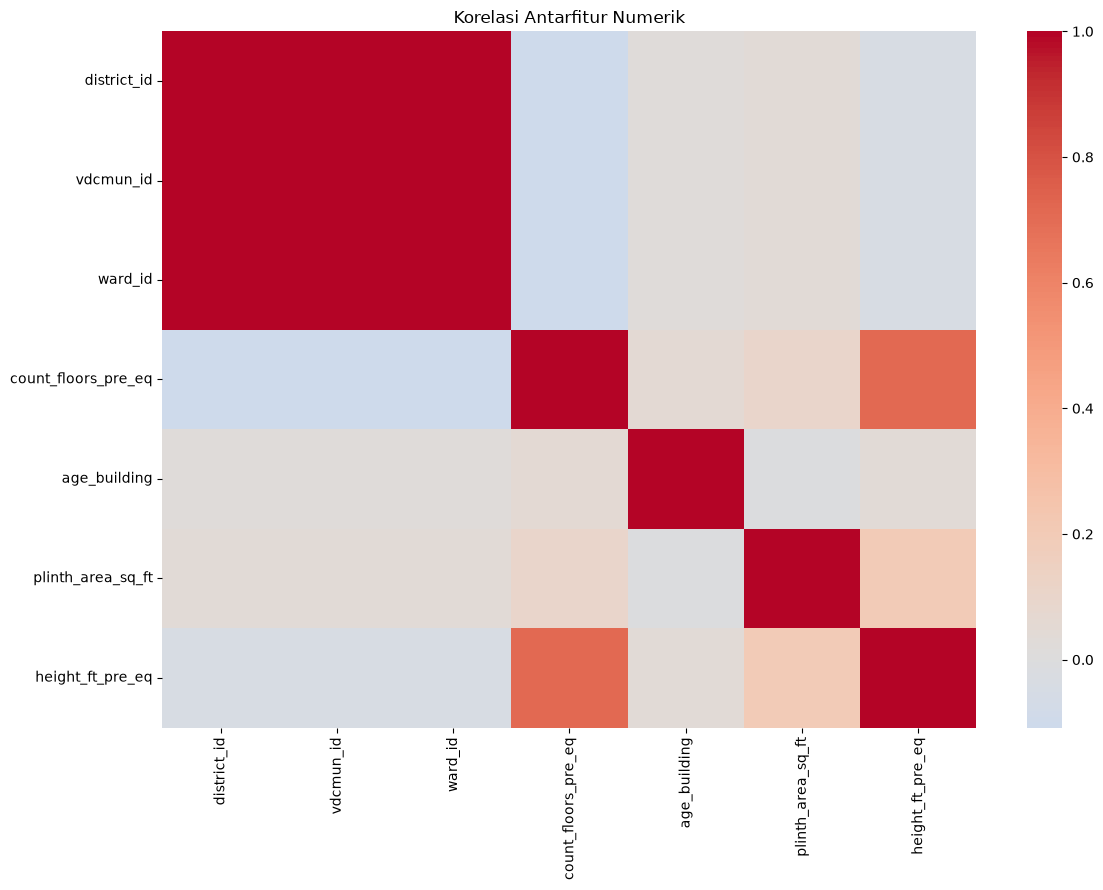

In [47]:
if len(numeric_cols) >= 2:
    corr = train[numeric_cols].corr()

    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, cmap="coolwarm", center=0)
    plt.title("Korelasi Antarfitur Numerik")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "correlation_heatmap.png", dpi=150)
    plt.show()


C:\Users\Agata Corinna\AppData\Local\Temp\ipykernel_47932\1964972806.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train.select_dtypes(


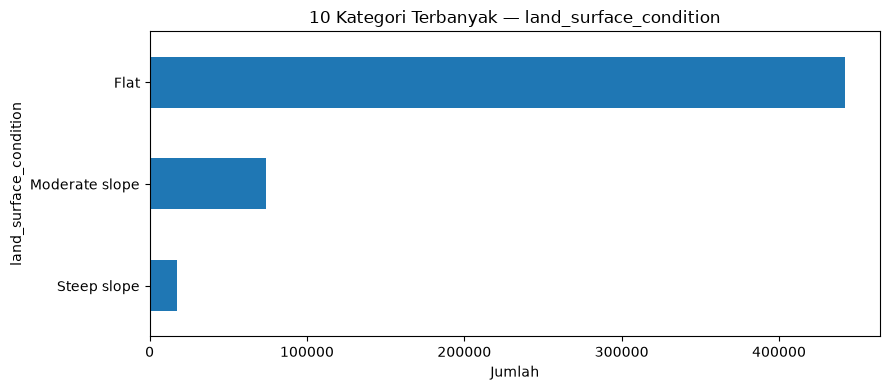

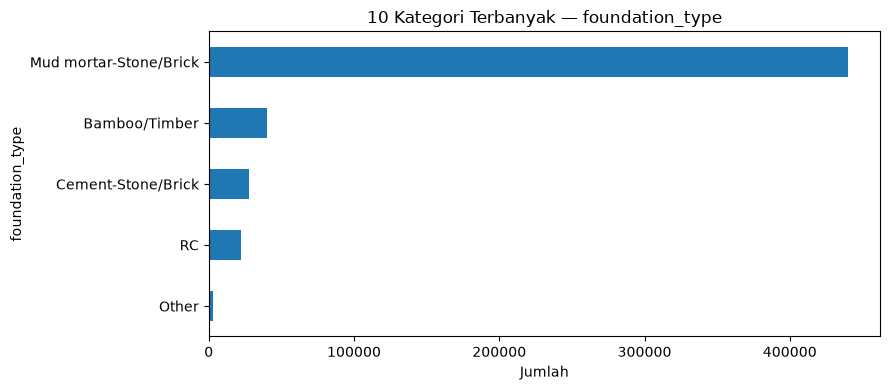

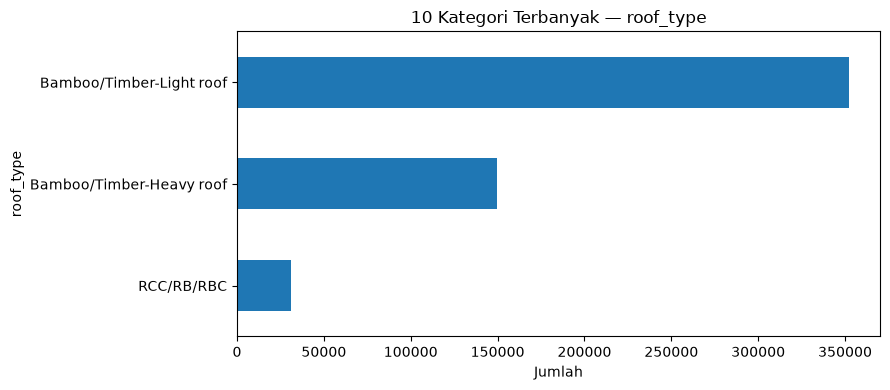

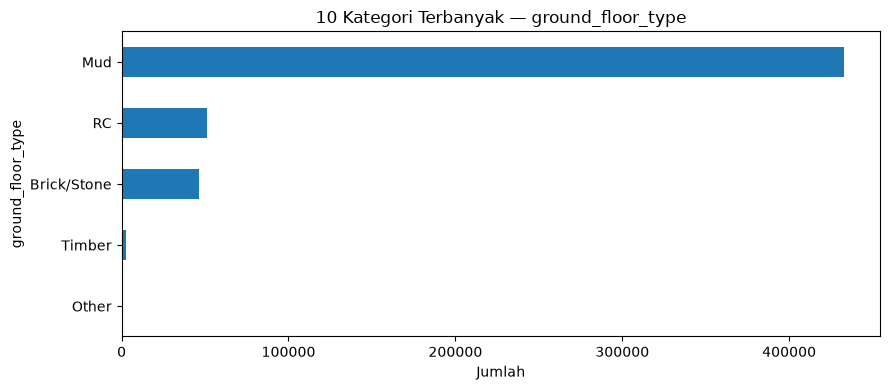

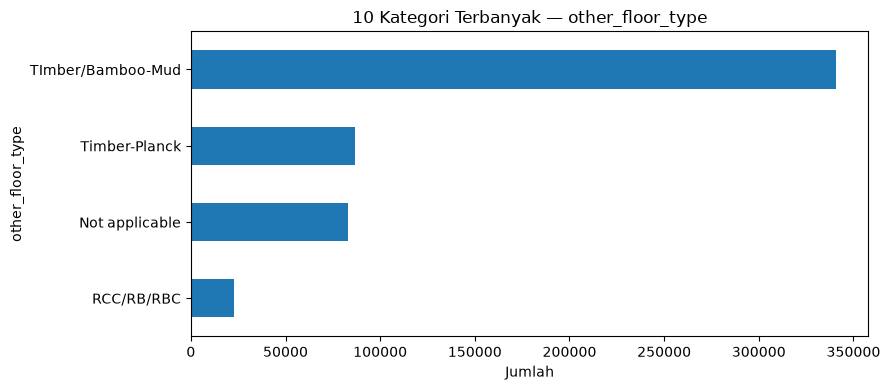

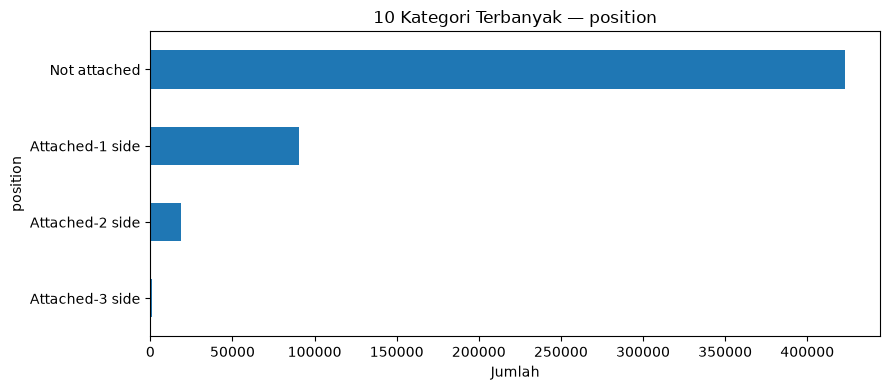

In [49]:
categorical_cols = train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

if TARGET in categorical_cols:
    categorical_cols.remove(TARGET)

for col in categorical_cols[:6]:
    counts = train[col].value_counts().head(10)

    plt.figure(figsize=(9, 4))
    counts.sort_values().plot(kind="barh")
    plt.title(f"10 Kategori Terbanyak — {col}")
    plt.xlabel("Jumlah")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"category_{col}.png", dpi=150)
    plt.show()
